In [1]:
# This is the python script performing the analysis of many LC-MS files for RiPP modifications
import pandas as pd
import pickle
from pathlib import Path
from plotting_analysis_functions import *
import re

In [2]:
# --- 1. Pre-flight Compatibility Formatting ---
# NOTE: master-dataframe construction now lives in plotting_analysis_functions.py as
# build_master_dataframe_from_groups(), sourced directly from each group's curated
# ReplicateGroupResults (*_manually_reviewed.pkl.gz) via generate_modification_state_matrix(),
# rather than from the older '_CURATED_APPROVED.pkl' report format. See the next cell.

def prepare_dataframe_for_plotting(df: pd.DataFrame) -> pd.DataFrame:
    """
    Guarantees that columns and categorical fields perfectly match the exact
    expectations of your custom calculation and alignment plotting functions.
    """
    plot_df = df.copy()

    # 1. Map alternative column names to match your strict function expectations
    column_mappings = {
        'group_name': 'experiment_id',       # Maps group_name to experiment_id
        'peak_area': 'area',
        'target_sequence': 'peptide_sequence',
        'cluster_id': 'cut_id'
    }

    for old_col, new_col in column_mappings.items():
        if old_col in plot_df.columns and new_col not in plot_df.columns:
            plot_df[new_col] = plot_df[old_col]

    # Ensure 'target_sequence' exists (keep a copy of the unmodified peptide string)
    if 'target_sequence' not in plot_df.columns and 'peptide_sequence' in plot_df.columns:
        plot_df['target_sequence'] = plot_df['peptide_sequence']

    # 2. Since this data is already curated (only manually-approved peaks make it into
    # generate_modification_state_matrix()), treat everything as accepted 'Gold' if the
    # 'tier' column isn't explicitly present.
    if 'tier' not in plot_df.columns:
        plot_df['tier'] = 'Gold'

    # 3. Handle modification string conversions expected by your calculator loop
    if 'target_modifications' in plot_df.columns:
        # Standardize string format to look like your check: "{'unmodified': None}"
        plot_df['modification_state'] = plot_df['target_modifications'].astype(str).replace({
            "{'unmodified': None}": "{'unmodified': None}",
            "unmodified": "{'unmodified': None}"
        })
    elif 'modification_state' not in plot_df.columns:
        plot_df['modification_state'] = "{'unmodified': None}"

    # 4. Final safety fallbacks for columns that absolutely must exist
    required_cols = ['experiment_id', 'sample_id', 'peptide_sequence', 'cut_id', 'enzyme', 'precursor_name', 'area']
    for col in required_cols:
        if col not in plot_df.columns:
            plot_df[col] = 'N/A' if col != 'area' else 0.0

    return plot_df

In [3]:
from pathlib import Path
from plotting_analysis_functions import build_master_dataframe_from_groups

# --- Configuration ---
REPORTS_PATH = r'D:\Spliceotide_Data_Analysis\output_reports_flasks'

# Build the master DataFrame directly from every group's curated ReplicateGroupResults
# (one *_manually_reviewed.pkl.gz per group, produced by peak_reviewing_pipeline.py). Experiment
# metadata (required_grouping_cols, sample_id, precursor_name, peptide_sequence, core
# coordinates, etc.) is pulled straight from each replicate's MSExperiment object, so no separate
# metadata Excel merge is needed anymore.
master_df = build_master_dataframe_from_groups(REPORTS_PATH)

Found 81 manually reviewed group file(s) under: D:\Spliceotide_Data_Analysis\output_reports_flasks
Successfully loaded ReplicateGroupResults from: D:\Spliceotide_Data_Analysis\output_reports_flasks\artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-560_24_TEV\artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-560_24_TEV_manually_reviewed.pkl.gz
Successfully loaded ReplicateGroupResults from: D:\Spliceotide_Data_Analysis\output_reports_flasks\artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-560_30_TEV\artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-560_30_TEV_manually_reviewed.pkl.gz
Successfully loaded ReplicateGroupResults from: D:\Spliceotide_Data_Analysis\output_reports_flasks\artificial_peptides_TJ-C-675_HypX-HypY_TJ-C-560_24_TEV\artificial_peptides_TJ-C-675_HypX-HypY_TJ-C-560_24_TEV_manually_reviewed.pkl.gz
Successfully loaded ReplicateGroupResults from: D:\Spliceotide_Data_Analysis\output_reports_flasks\artificial_peptides_TJ-C-676_HypX-HypY_TJ-C-560_24_TEV\artificial_peptides_TJ-C-676_HypX-HypY_TJ-C-5

In [4]:
from plotting_analysis_functions import extract_best_cut_charge, collapse_modification_replicates

# --- 2. Data Preparation Chain ---
# Step A: For every experimental group, pick the single best (cut, charge) combination
# (highest average quality_score across replicates/modifications, then highest average area).
best_cut_charge_df = extract_best_cut_charge(master_df)

# Step B: Collapse each replicate down to its unmodified peptide, computing
# total_modification_ratio (aliased as mod_ratio) = unmodified area / overall_signal_intensity.
processed_ratios_df = collapse_modification_replicates(best_cut_charge_df)

print(f"Summary data ready. Calculated modification ratios for {len(processed_ratios_df)} features.")

Summary data ready. Calculated modification ratios for 116 features.


In [10]:
# we make a new column with the entire peptide core sequence, we use the "peptide_sequence_meta" column and the "core_start" to extract the core sequence. This is useful for plotting and analysis.
processed_ratios_df["full_core_sequence"] = processed_ratios_df.apply(
    lambda row: row["peptide_sequence_meta"][int(row["core_start"])-2:],
    axis=1
)
# we strip the stop codons (*) from the string
processed_ratios_df["full_core_sequence"] = processed_ratios_df["full_core_sequence"].str.replace("*", "", regex=False)

In [16]:
# we make new column with the solubility tag
tag_names = ["Fh8-chaos", "Fh8",  "RSTN", "Pfu-MBP", "sfGFP", "Fka-MTR"]
processed_ratios_df["solubility_tag"] = processed_ratios_df["precursor_name"].apply(
    lambda x: next((tag for tag in tag_names if tag in x), "None")
)
processed_ratios_df["expression_temperature_fancy"] = processed_ratios_df["expression_temperature"].apply(
    lambda x: f"{x}°C")
def split_core_name(x):
    if re.search("HypAc-TEV", x):
        core = x.split("HypAc-TEV-")[-1]
    elif re.search("HypAc", x):
        core = x.split("HypAc-")[-1]
    elif re.search("HypA[1-9]-", x):
        core = x.split("HypA[1-9]-")[-1]
    elif re.search("PlpA3-TEV", x):
        core = x.split("PlpA3-TEV-")[-1]
    return core
processed_ratios_df["core_name"] = processed_ratios_df["precursor_name"].apply(lambda x: split_core_name(x))
# if the str conatins HypAc then the leader is HypAc otherwise "native"
processed_ratios_df["leader"] = processed_ratios_df["precursor_name"].apply(
    lambda x: "HypAc" if "HypAc-TEV" in x else "native")
processed_ratios_df["core"] = processed_ratios_df["precursor_name"].apply(lambda x: x[-5::])

processed_ratios_df.to_pickle(r"summary_data_files/flask_expressions_processed_ratios_df.pkl")

In [17]:

artificial_peptides = processed_ratios_df[
    (processed_ratios_df["precursor_name"].str.contains("Artificial")) |
    (processed_ratios_df["precursor_name"].str.contains("Boc-")) |
    (processed_ratios_df["precursor_name"].str.contains("LQYG"))
]




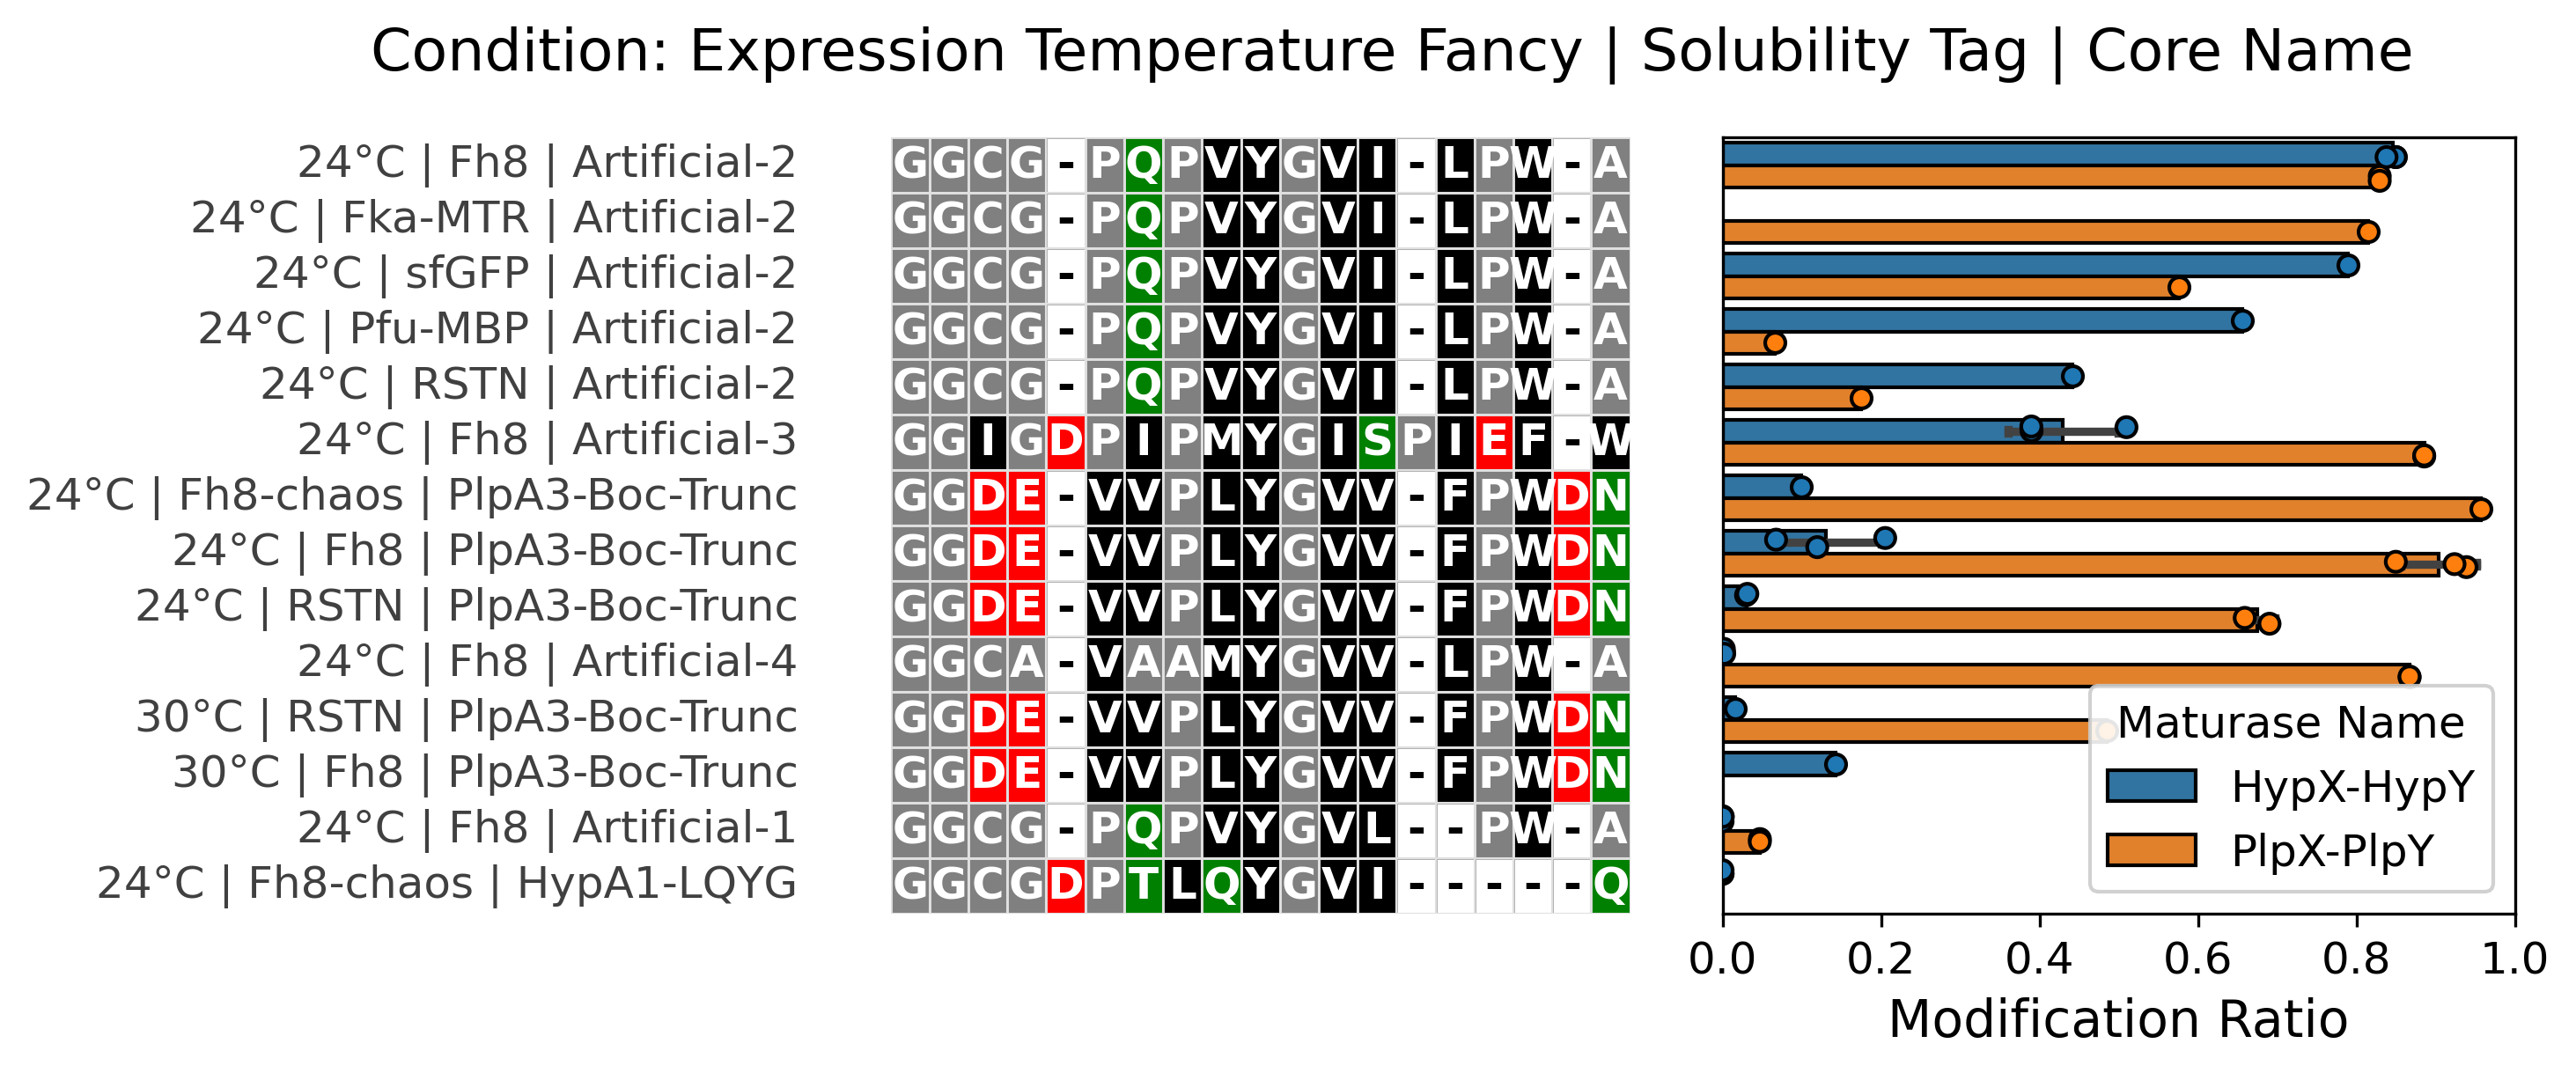

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


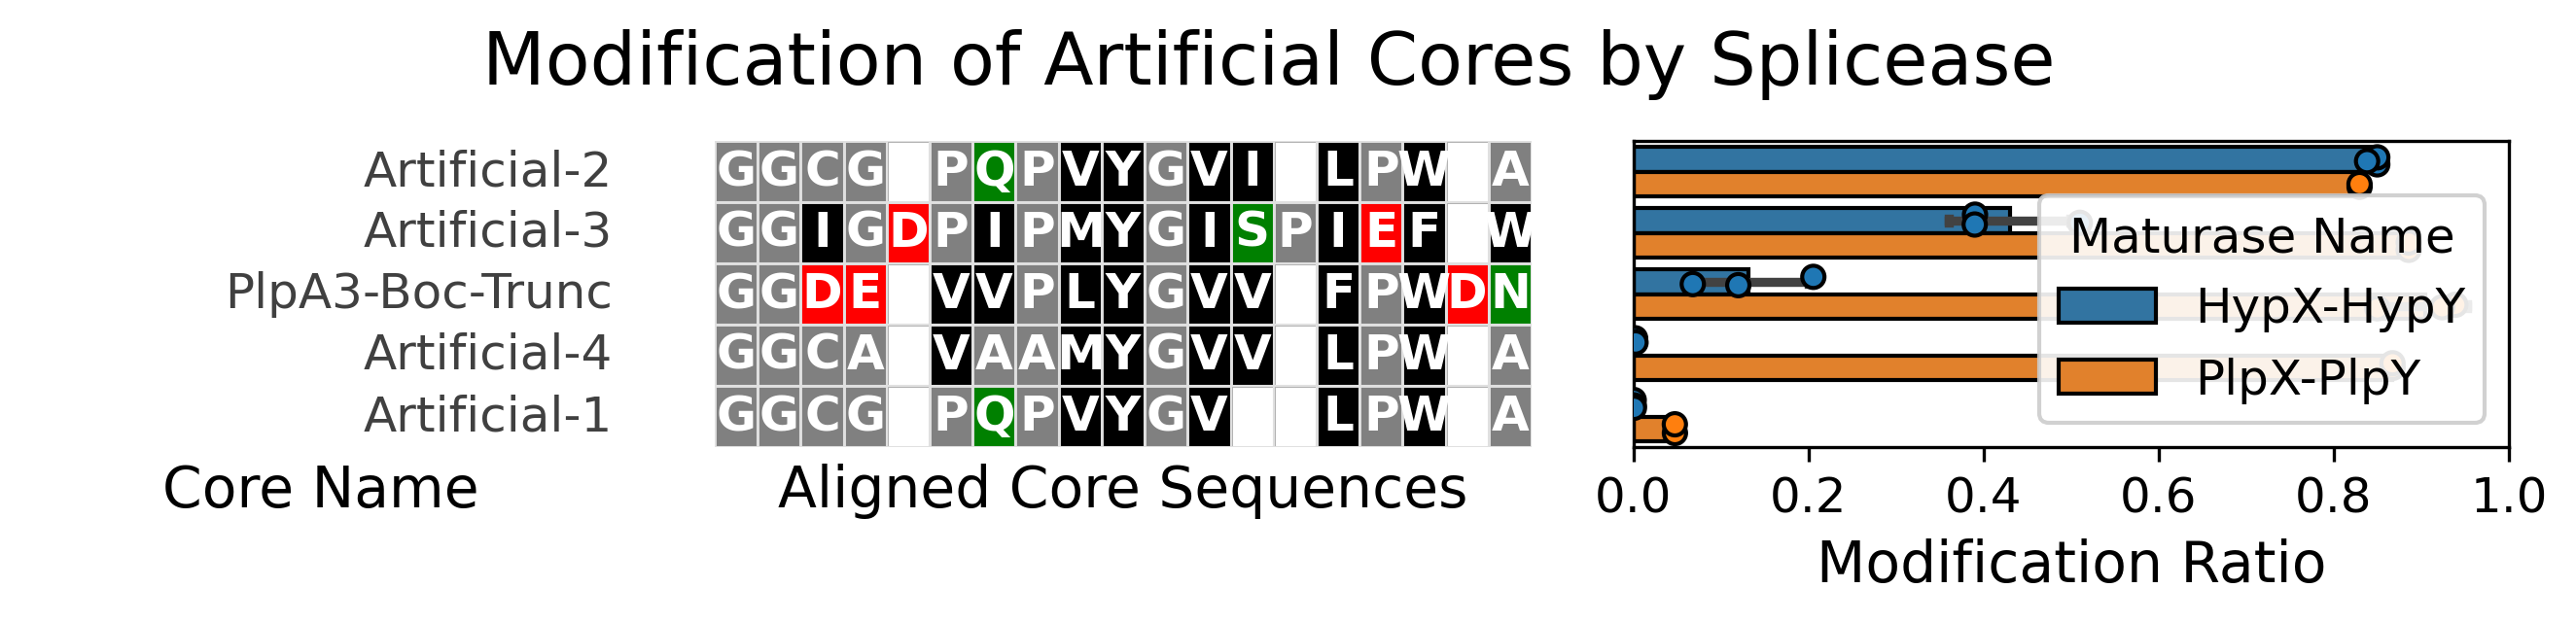

In [18]:
create_grouped_alignment_plot(
    artificial_peptides,
    ref_sequence = "GGCGPQPVYGVILPWA",
    metadata_cols= ["expression_temperature_fancy", "solubility_tag", 'core_name'],
    color_scheme_name= "hydrophobicity",
    show_ddg= False,
    preset = 'poster',
    savepath = None,
    show_gaps=True,
    use_alignment = True,
    drop_identical = False,
    sequence_column = "full_core_sequence")

create_grouped_alignment_plot(
    artificial_peptides[(artificial_peptides["solubility_tag"]=="Fh8") & (artificial_peptides["expression_temperature"]==24)],
    ref_sequence = "GGCGPQPVYGVILPWA",
    metadata_cols= ['core_name'],
    color_scheme_name= "hydrophobicity",
    show_ddg= False,
    preset = 'poster',
    savepath = "summary_data_files/flask_artificial_peptides.eps",
    use_alignment = True,
    drop_identical = False,
    seqtitle="Aligned Core Sequences",
    metatitle="Core Name",
    suptitle="Modification of Artificial Cores by Splicease",
    sequence_column = "full_core_sequence")

In [13]:
artificial_peptides_plp = processed_ratios_df[
    (processed_ratios_df["maturase_name"] == "PlpX-PlpY") &
    (processed_ratios_df["precursor_name"].str.contains("Artificial"))]

artificial_peptides_hyp = processed_ratios_df[
    (processed_ratios_df["maturase_name"] == "HypX-HypY") &
    (processed_ratios_df["precursor_name"].str.contains("Artificial"))]


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


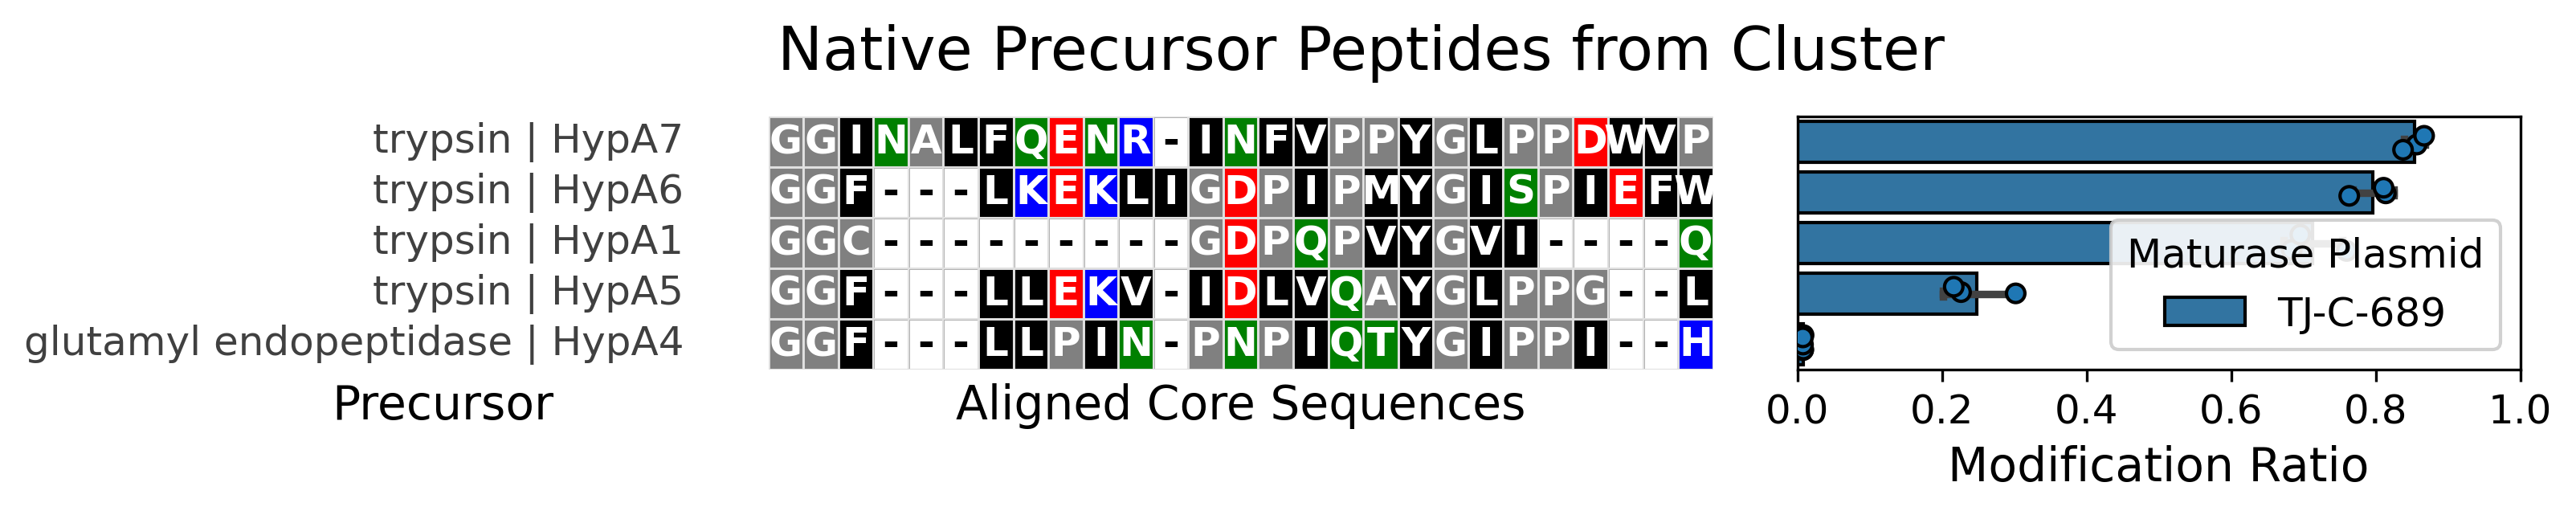

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


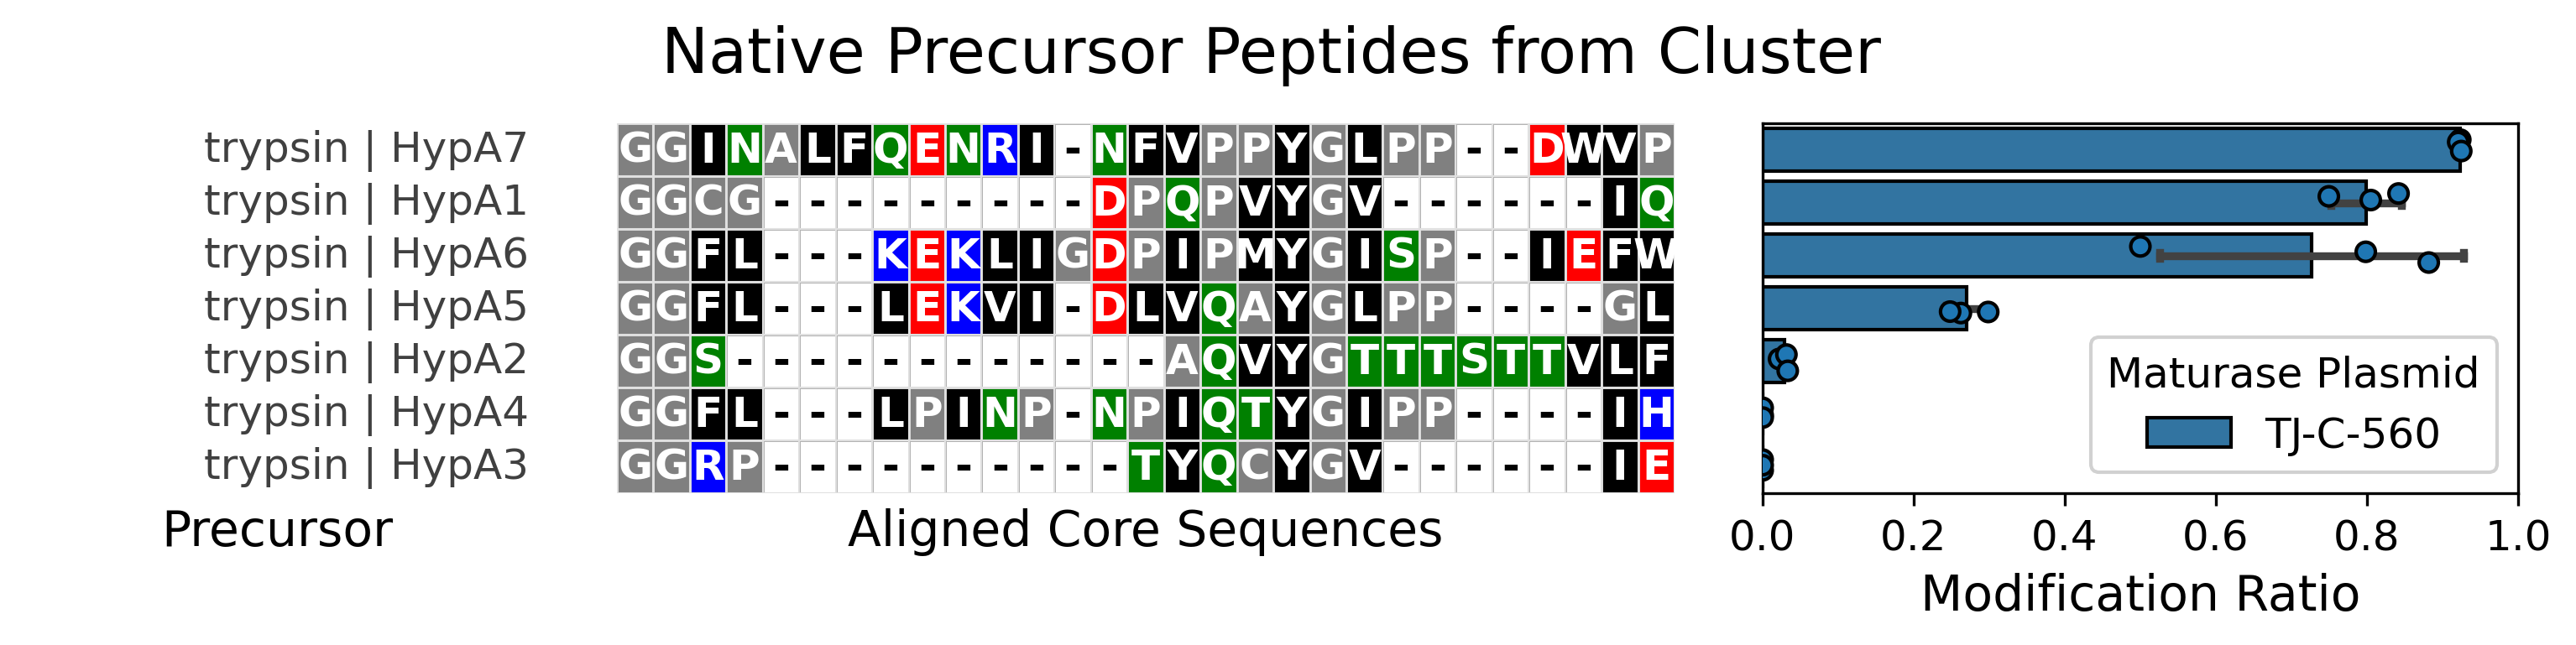

In [14]:
wild_type_peptides_hyella = processed_ratios_df[
    (processed_ratios_df["maturase_name"] == "HypX-HypY") & (
    (processed_ratios_df["precursor_name"].str.contains("HypA[1-9]{1}-HypA[1-9]{1}$")) |
    (processed_ratios_df["precursor_name"].str.contains("HypAc-HypA[1-9]{1}$"))
    )]

pleurocapsa_name = ["PlpA2", "PlpA3"]
pleurocapsa_seq = ["GGVDLSIFELLDEEPLFPIRPLYGLPI", "GGAVAAMYGVVFPWDNEFPWPRWGG"]
# we make a df from the two lists above
# 1. Create the stubs DataFrame matching your pipeline's column schema
stubs_df = pd.DataFrame({
    'full_core_sequence': pleurocapsa_seq,
    'core': pleurocapsa_name,  # Or map to whichever column splits your bars
    'mod_ratio': [0.0, 0.0],            # Defaulting to 0 if no modification occurred

    # Include your metadata columns here so the left-axis labels don't show 'nan'
    'solubility_tag': ['Control', 'Control'],
    'expression_temperature': ['N/A', 'N/A'],
    'maturase_plasmid': [None, None],
    'digestion': [None, None]
})

# 2. Append them to your master processed ratios dataframe
# (Using pd.concat is the modern, recommended alternative to .append)
hyella_plot_compare = pd.concat([wild_type_peptides_hyella, stubs_df], ignore_index=True)

create_grouped_alignment_plot(
    hyella_plot_compare[hyella_plot_compare["maturase_plasmid"] == "TJ-C-689"],
    ref_sequence = "None",
    hue_column = "maturase_plasmid",
    metadata_cols= ["digestion", "core"],
    color_scheme_name= "hydrophobicity",
    show_ddg= False,
    show_gaps=True,
    preset = 'poster',
    savepath = "summary_data_files/flask_wild_type_consensus_hyella.eps",
    use_alignment = True,
    drop_identical = False,
    metatitle="Precursor",
    seqtitle="Aligned Core Sequences",
    suptitle=r"Native Precursor Peptides from Cluster",
    sequence_column = "full_core_sequence")

create_grouped_alignment_plot(
    hyella_plot_compare[hyella_plot_compare["maturase_plasmid"] == "TJ-C-560"],
    ref_sequence = "None",
    hue_column = "maturase_plasmid",
    metadata_cols= ["digestion", "core"],
    color_scheme_name= "hydrophobicity",
    show_ddg= False,
    show_gaps=True,
    preset = 'poster',
    savepath = "summary_data_files/flask_wild_type_wild_hyella.eps",
    use_alignment = True,
    drop_identical = False,
    metatitle="Precursor",
    seqtitle="Aligned Core Sequences",
    suptitle=r"Native Precursor Peptides from Cluster",
    sequence_column = "full_core_sequence")


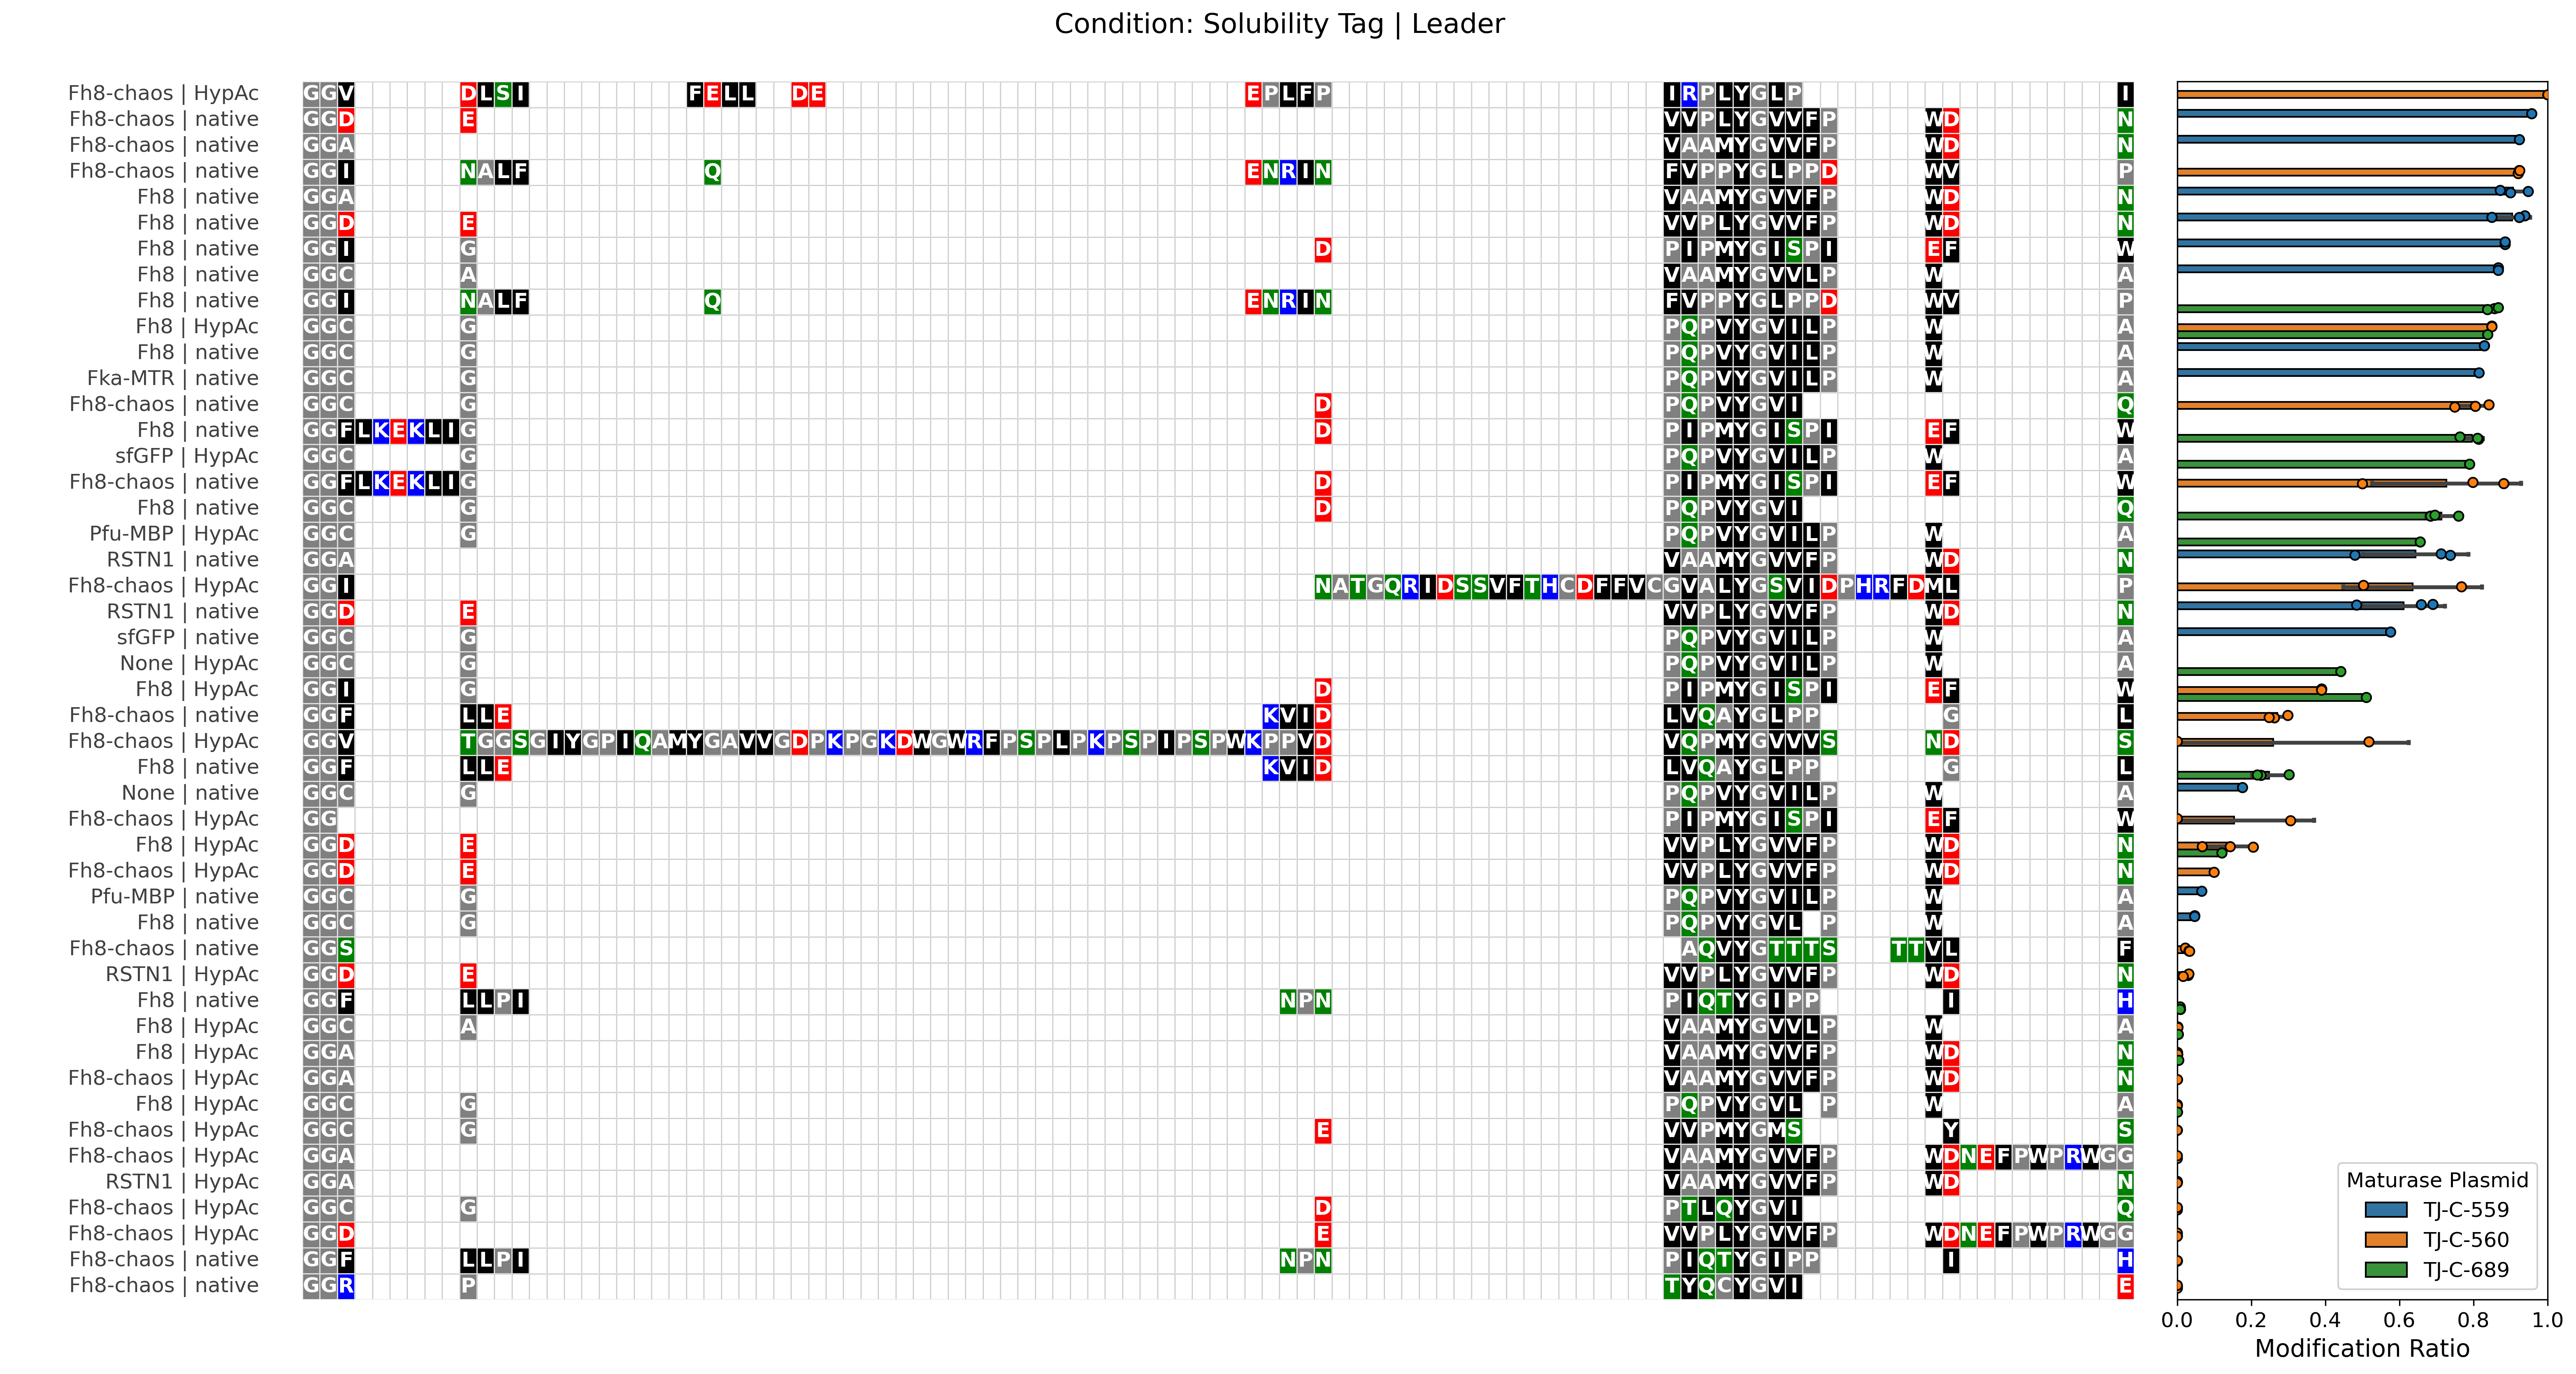

In [15]:
create_grouped_alignment_plot(
    processed_ratios_df,
    ref_sequence = "None",
    hue_column = "maturase_plasmid",
    metadata_cols= ["solubility_tag", "leader"],
    color_scheme_name= "hydrophobicity",
    show_ddg= False,
    preset = 'poster',
    savepath = None,
    use_alignment = True,
    drop_identical = False,
    sequence_column = "full_core_sequence")